In [22]:
from typing import List, TypedDict, Literal
import time
import os

from langchain_groq import ChatGroq
from pydantic import BaseModel, Field
from langchain_community.document_loaders import PyPDFLoader
from langchain_community.vectorstores import FAISS
from langchain_openai import OpenAIEmbeddings, ChatOpenAI
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate

from langgraph.graph import StateGraph, START, END
from dotenv import load_dotenv
load_dotenv()

True

In [ ]:
# doc = PyPDFLoader("./data/Company_Policies.pdf").load()+PyPDFLoader("./data/Company_Profile.pdf").load() + PyPDFLoader("./data/Product_and_pricing.pdf").load()
# len(doc)

6

In [ ]:
## chunks = RecursiveCharacterTextSplitter(chunk_size=900, chunk_overlap=150).split_documents(doc)
# for d in chunks:
#     d.page_content = d.page_content.encode("utf-8", "ignore").decode("utf-8", "ignore")

In [ ]:
# len(chunks)

10

In [8]:
# embeddings = GoogleGenerativeAIEmbeddings(model="models/gemini-embedding-001")
embeddings = OpenAIEmbeddings(
    model="text-embedding-3-small",
    openai_api_key=os.getenv("OPENROUTER_API_KEY"),
    openai_api_base="https://openrouter.ai/api/v1",
)

In [ ]:
# vector_store = FAISS.from_documents(chunks, embeddings)
# vector_store.save_local("nexaAI_index")

In [36]:
vector_store = FAISS.load_local("nexaAI_index", embeddings, allow_dangerous_deserialization=True)
retriever = vector_store.as_retriever(search_type='similarity', search_kwargs={'k':4})

In [12]:

# llm = ChatOpenAI(
#     # model="nvidia/nemotron-3.5-lightning:free",  # or any other OpenRouter model e.g. "google/gemini-2.0-flash-001"
#     model="openai/gpt-6-luna",
#     openai_api_key=os.getenv("OPENROUTER_API_KEY"),
#     openai_api_base="https://openrouter.ai/api/v1",
#     temperature=0.3,
# )

llm = ChatGroq(
    model="openai/gpt-oss-120b", 
    temperature=0.2,
    max_tokens=800
)

In [50]:
class state(TypedDict):
    question : str
    need_retrieval: bool

    docs : list[Document]
    relevant_docs : list[Document]

    context: str
    answer : str

    issup : Literal["fully_supported", "partially_supported", "no_support"]
    evidence : List[str]

    retries : int
    

In [14]:
def retrieve(state):
    q = state["question"]
    return {"docs" : retriever.invoke(q)}

In [16]:
prompt = ChatPromptTemplate.from_messages(
    [
        ("system", "Answer only from the context. If not in context, say you don't know."),
        ("human", "Question: {question}\n\nContext:\n{context}"),
    ]
)

def generate(state):
    context = "/n/n".join(d.page_content for d in state["docs"])
    chain = prompt | llm
    response = chain.invoke({"question": state["question"], "context":context})
    # print(response)

    return {"answer": response.content}

In [17]:
class RelvenceDecision(BaseModel):
    is_relevant : bool = Field(description="True if the document helps answer the question, else False.")

is_relevant_prompt = ChatPromptTemplate.from_messages(
    [   
        (
            "system",
            "You are judging document relevance.\n"
            "Return JSON that matches this schema:\n"
            "{{'is_relevant': boolean}}\n\n"
            "A document is relevant if it contains information useful for answering the question."
        ),
        (
            "human",
            "Question:\n{question}\n\nDocument:\n{document}"
        )
    ]
)

relvenceLLM = llm.with_structured_output(RelvenceDecision)

def is_relevent(state : state):
    relevent_docs : List[Document] = []

    for doc in state["docs"]:
        out = relvenceLLM.invoke(
            is_relevant_prompt.format_messages(
                question=state["question"],
                document=doc.page_content
            )
        )

        if out.is_relevant:
            relevent_docs.append(doc)
    
    return {"relevant_docs": relevent_docs} 

In [18]:
res = (is_relevant_prompt | relvenceLLM).invoke({"question":"hi","document": "doc"})

In [19]:
res.is_relevant

False

In [20]:
class RetrieveDecision(BaseModel):
    should_retrieve: bool = Field(
        ...,
        description="True if external documents are needed to answer reliably, else False."
    )
    
decide_retrieval_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You decide whether retrieval is needed.\n"
            "Return JSON that matches this schema:\n"
            "{{'should_retrieve': boolean}}\n\n"
            "Guidelines:\n"
            "- should_retrieve=True if answering requires specific facts, citations, or info likely not in the model.\n"
            "- should_retrieve=False for general explanations, definitions, or reasoning that doesn't need sources.\n"
            "- If unsure, choose True."
        ),
        ("human", "Question: {question}"),
    ]
)

should_retrieve_llm = llm.with_structured_output(RetrieveDecision)

def decide_retrieval(state: "state"):
    decision: RetrieveDecision = should_retrieve_llm.invoke(
        decide_retrieval_prompt.format_messages(question=state["question"])
    )
    return {"need_retrieval": decision.should_retrieve}

In [21]:
direct_generation_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "Answer the question using only your general knowledge.\n"
            "Do NOT assume access to external documents.\n"
            "If you are unsure or the answer requires specific sources, say:\n"
            "'I don't know based on my general knowledge.'"
        ),
        ("human", "{question}"),
    ]
)


def generate_direct(state: state):
    out = llm.invoke(
        direct_generation_prompt.format_messages(
            question=state["question"]
        )
    )
    return {
        "answer": out.content
    }

In [23]:
def route_after_decision(state : state) -> Literal["retrieve", "generate_direct"]:
    if state["need_retrieval"]:
        return "retrieve"
    return "generate_direct"

In [24]:
rag_generation_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are a business RAG assistant.\n"
            "Answer the user's question using ONLY the provided context.\n"
            "If the context does not contain enough information, say:\n"
            "'No relevant document found.'\n"
            "Do not use outside knowledge.\n"
        ),
        (
            "human",
            "Question:\n{question}\n\n"
            "Context:\n{context}\n"
        ),
    ]
)

def generate_from_context(state: state):
    # Stuff relevant docs into one block
    context = "\n\n---\n\n".join(
        [d.page_content for d in state.get("relevant_docs", [])]
    ).strip()

    if not context:
        return {"answer": "No relevant document found.", "context": ""}

    out = llm.invoke(
        rag_generation_prompt.format_messages(
            question=state["question"],
            context=context
        )
    )
    return {"answer": out.content, "context": context}

In [27]:
class IsSUPDecision(BaseModel):
    issup: Literal["fully_supported", "partially_supported", "no_support"]
    evidence: List[str] = Field(default_factory=list)

issup_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are verifying whether the ANSWER is supported by the CONTEXT.\n"
            "Return JSON with keys: issup, evidence.\n"
            "issup must be one of: fully_supported, partially_supported, no_support.\n\n"
            "How to decide issup:\n"
            "- fully_supported:\n"
            "  Every meaningful claim is explicitly supported by CONTEXT, and the ANSWER does NOT introduce\n"
            "  any qualitative/interpretive words that are not present in CONTEXT.\n"
            "  (Examples of disallowed words unless present in CONTEXT: culture, generous, robust, designed to,\n"
            "  supports professional development, best-in-class, employee-first, etc.)\n\n"
            "- partially_supported:\n"
            "  The core facts are supported, BUT the ANSWER includes ANY abstraction, interpretation, or qualitative\n"
            "  phrasing not explicitly stated in CONTEXT (e.g., calling policies 'culture', saying leave is 'generous',\n"
            "  or inferring outcomes like 'supports professional development').\n\n"
            "- no_support:\n"
            "  The key claims are not supported by CONTEXT.\n\n"
            "Rules:\n"
            "- Be strict: if you see ANY unsupported qualitative/interpretive phrasing, choose partially_supported.\n"
            "- If the answer is mostly unrelated to the question or unsupported, choose no_support.\n"
            "- Evidence: include up to 3 short direct quotes from CONTEXT that support the supported parts.\n"
            "- Do not use outside knowledge."
        ),
        (
            "human",
            "Question:\n{question}\n\n"
            "Answer:\n{answer}\n\n"
            "Context:\n{context}\n"
        ),
    ]
)



issup_llm = llm.with_structured_output(IsSUPDecision)

def is_sup(state: state):
    decision: IsSUPDecision = issup_llm.invoke(
        issup_prompt.format_messages(
            question=state["question"],
            answer=state.get("answer", ""),
            context=state.get("context", ""),
        )
    )
    return {"issup": decision.issup, "evidence": decision.evidence}

In [59]:
revise_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are a STRICT reviser.\n\n"
            "You must output based on the following format:\n\n"
            "FORMAT (quote-only answer):\n"
            "- <direct quote from the CONTEXT>\n"
            "- <direct quote from the CONTEXT>\n\n"
            "Rules:\n"
            "- Use ONLY the CONTEXT.\n"
            "- Do NOT add any new words besides bullet dashes and the quotes themselves.\n"
            "- Do NOT explain anything.\n"
            "- Do NOT say 'context', 'not mentioned', 'does not mention', 'not provided', etc.\n"
        ),
        (
            "human",
            "Question:\n{question}\n\n"
            "Current Answer:\n{answer}\n\n"
            "CONTEXT:\n{context}"
        ),
    ]
)


def revise_answer(state:state):
    out = llm.invoke(
        revise_prompt.format_messages(
            question=state["question"],
            answer=state.get("answer", ""),
            context=state.get("context", ""),
        )
    )

    return {
        "answer" : out.content,
        "retries" : state.get("retries", 0) + 1
    }

In [46]:
def accept_answer(state : state):
    return {}

In [56]:
def route_after_issup(state : state) -> Literal["revise_answer", "accept_answer"]:
    if state["issup"] == "fully_supported":
        return "accept_answer"
    if state.get("retries", 0) > 3:
        return "accept_answer"
    return "revise_answer"

In [60]:
graph = StateGraph(state)
graph.add_node("retrieve", retrieve)

graph.add_node("decide_retrieval", decide_retrieval)

graph.add_node("generate_direct", generate_direct)
graph.add_node("is_relevant", is_relevent)
graph.add_node("generate_from_context", generate_from_context)
graph.add_node("is_sup", is_sup)
graph.add_node("route_after_issup", route_after_issup)
graph.add_node("revise_answer", revise_answer)
graph.add_node("accept_answer", accept_answer)

graph.add_edge(START, "decide_retrieval")
graph.add_conditional_edges("decide_retrieval", route_after_decision,{
    "generate_direct":"generate_direct",
    "retrieve": "retrieve"
}
)

graph.add_edge("retrieve", "is_relevant")
graph.add_edge("is_relevant", "generate_from_context")
graph.add_edge("generate_from_context", "is_sup")
graph.add_conditional_edges("is_sup", route_after_issup,{
    "accept_answer":"accept_answer",
    "revise_answer": "revise_answer"
}
)
graph.add_edge("revise_answer", "is_sup")
graph.add_edge("accept_answer", END)
graph.add_edge("generate_direct", END)


app = graph.compile()

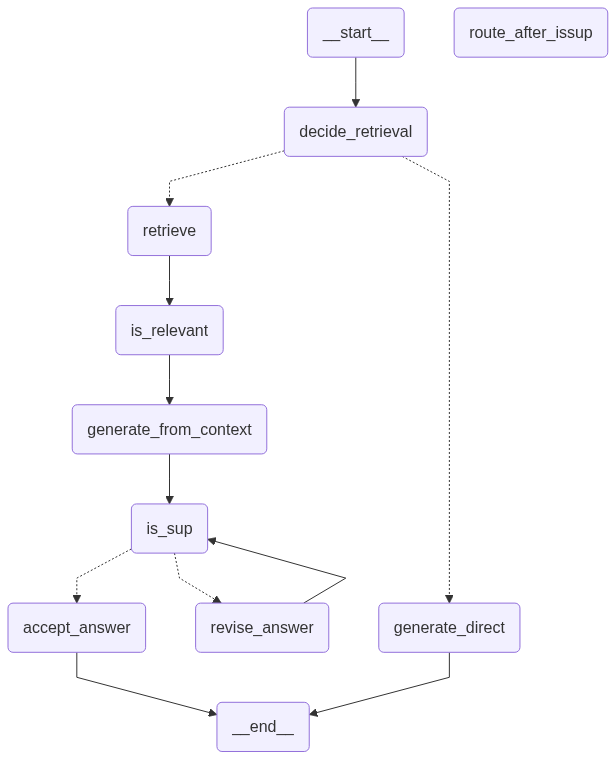

In [61]:
app

In [71]:
res = app.invoke({"question": "what duration of free trial days is given by hr","need_retrieval": 0, "docs": [], "relevant_docs":[], "answer": "","retries": 0})


In [73]:
res

{'question': 'what duration of free trial days is given by hr',
 'need_retrieval': True,
 'docs': [Document(id='0760f990-789c-49f1-97a3-acf775f4501c', metadata={'producer': 'ReportLab PDF Library - www.reportlab.com', 'creator': '(unspecified)', 'creationdate': '2026-02-14T13:07:17+00:00', 'author': '(anonymous)', 'keywords': '', 'moddate': '2026-02-14T13:07:17+00:00', 'subject': '(unspecified)', 'title': '(anonymous)', 'trapped': '/False', 'source': './data/Company_Policies.pdf', 'total_pages': 2, 'page': 1, 'page_label': '2'}, page_content='\x7f\nWritten warning\n\x7f\nSuspension\n\x7f\nTermination of employment in severe cases'),
  Document(id='07b5ffcb-f216-4a53-b45e-0c98c056b1cd', metadata={'producer': 'ReportLab PDF Library - www.reportlab.com', 'creator': '(unspecified)', 'creationdate': '2026-02-14T13:07:17+00:00', 'author': '(anonymous)', 'keywords': '', 'moddate': '2026-02-14T13:07:17+00:00', 'subject': '(unspecified)', 'title': '(anonymous)', 'trapped': '/False', 'source': '